## Computational Analysis of Genomic Sequences: Feature Extraction and Data Preparation



In [ ]:
!pip install biopython pandas matplotlib seaborn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 23.9 MB/s eta 0:00:00


### 1. Data Acquisition and Preprocessing

This section details the acquisition and preprocessing of genomic sequence data from the NCBI Nucleotide database. Sequences from diverse species (animals, bacteria, plants) were retrieved, adhering to specific length criteria (500-2000 bp). A custom `get_taxonomy_hierarchy` function classifies species into higher-level taxonomic domains for stratified sampling.

In [ ]:
species_list = [
    ("9606", "Homo sapiens"),              # human
    ("10090", "Mus musculus"),             # mouse
    ("10116", "Rattus norvegicus"),        # rat
    ("9913", "Bos taurus"),

    ("562", "Escherichia coli"),
    ("1280", "Staphylococcus aureus"),
    ("287", "Pseudomonas aeruginosa"),
    ("1423", "Bacillus subtilis"),

    ("3702", "Arabidopsis thaliana"),
    ("4577", "Zea mays"),                 # corn
    ("4530", "Oryza sativa"),             # rice
    ("3635", "Glycine max")               #soybean
]

#### 1.1 Taxonomy-Guided Sequence Retrieval

This section defines target species and initiates sequence retrieval from NCBI. A specific number of sequences per species are queried, ensuring lengths within a predefined range (500-2000 bp). This aims to create a balanced dataset across taxonomic groups for robust model training.

In [ ]:
import time
import pandas as pd
from Bio import Entrez, SeqIO
import random


Entrez.email = ""
MIN_LEN = 500
MAX_LEN = 2000
MIN_RECORDS = 300
MAX_RECORDS = 500

def get_taxonomy_hierarchy(taxid):

    try:
        handle = Entrez.efetch(db="taxonomy", id=taxid, retmode="xml")
        record = Entrez.read(handle)
        handle.close()

        lineage = record[0].get("Lineage", "")


        if "Viridiplantae" in lineage:
            domain_label = "Plant"
        elif "Metazoa" in lineage:
            domain_label = "Animal"
        elif "Fungi" in lineage:
            domain_label = "Fungi"
        elif "Bacteria" in lineage:
            domain_label = "Bacteria"
        elif "Archaea" in lineage:
            domain_label = "Archaea"
        else:
            domain_label = "Other Eukaryote"

        return domain_label
    except Exception as e:
        return "Unknown"

dataset = []


for taxid, name in species_list:
    domain_group = get_taxonomy_hierarchy(taxid)
    print(f"Processing {name} | Group: {domain_group}...")

    target_count = random.randint(MIN_RECORDS, MAX_RECORDS)

    search_term = f"txid{taxid}[Organism] AND {MIN_LEN}:{MAX_LEN}[SLEN] AND srcdb_refseq[PROP]"

    try:
        handle = Entrez.esearch(db="nucleotide", term=search_term, retmax=target_count + 50)
        id_list = Entrez.read(handle)["IdList"]
        handle.close()

        if len(id_list) < target_count:
            search_term = f"txid{taxid}[Organism] AND {MIN_LEN}:{MAX_LEN}[SLEN]"
            handle = Entrez.esearch(db="nucleotide", term=search_term, retmax=target_count + 50)
            id_list = Entrez.read(handle)["IdList"]
            handle.close()

        selected_ids = random.sample(id_list, min(len(id_list), target_count))

        if selected_ids:
            fetch_handle = Entrez.efetch(db="nucleotide", id=",".join(selected_ids), rettype="fasta", retmode="text")
            records = list(SeqIO.parse(fetch_handle, "fasta"))
            fetch_handle.close()

            for rec in records:
                dataset.append({
                    "species": name,
                    "domain": domain_group,
                    "accession": rec.id,
                    "sequence": str(rec.seq).upper(),
                    "length": len(rec.seq),
                    "gc_content": float(str(rec.seq).upper().count('G') + str(rec.seq).upper().count('C')) / len(rec.seq)
                })
            print(f"Successfully added {len(records)} sequences.")

        time.sleep(1)
    except Exception as e:
        print(f"Error on {name}: {e}")

df = pd.DataFrame(dataset)
df.to_csv("taxonomy_final_dataset.csv", index=False)

Processing Homo sapiens | Group: Animal...
Successfully added 431 sequences.
Processing Mus musculus | Group: Animal...
Successfully added 443 sequences.
Processing Rattus norvegicus | Group: Animal...
Successfully added 381 sequences.
Processing Bos taurus | Group: Animal...
Successfully added 318 sequences.
Processing Escherichia coli | Group: Bacteria...
Successfully added 403 sequences.
Processing Staphylococcus aureus | Group: Bacteria...
Successfully added 310 sequences.
Processing Pseudomonas aeruginosa | Group: Bacteria...
Successfully added 499 sequences.
Processing Bacillus subtilis | Group: Bacteria...
Successfully added 472 sequences.
Processing Arabidopsis thaliana | Group: Plant...
Successfully added 360 sequences.
Processing Zea mays | Group: Plant...
Successfully added 444 sequences.
Processing Oryza sativa | Group: Plant...
Successfully added 418 sequences.
Processing Glycine max | Group: Plant...
Successfully added 446 sequences.


### 2. Exploratory Data Analysis (EDA) of Raw Sequence Characteristics

Initial Exploratory Data Analysis (EDA) characterizes the retrieved sequences. This includes visualizing sequence distribution per species, length distribution, and GC content. These insights help understand dataset properties and identify potential biases.

#### 2.1 Sequence Count Distribution

This visualization shows the number of sequences retrieved per species, providing an overview of the dataset's composition. A balanced representation is important for robust model training.

#### 2.1 Sequence Count Distribution

This visualization illustrates the number of sequences successfully retrieved for each specified species, providing a quantitative overview of the dataset's composition. A relatively balanced representation across species is desirable for robust machine learning model training.

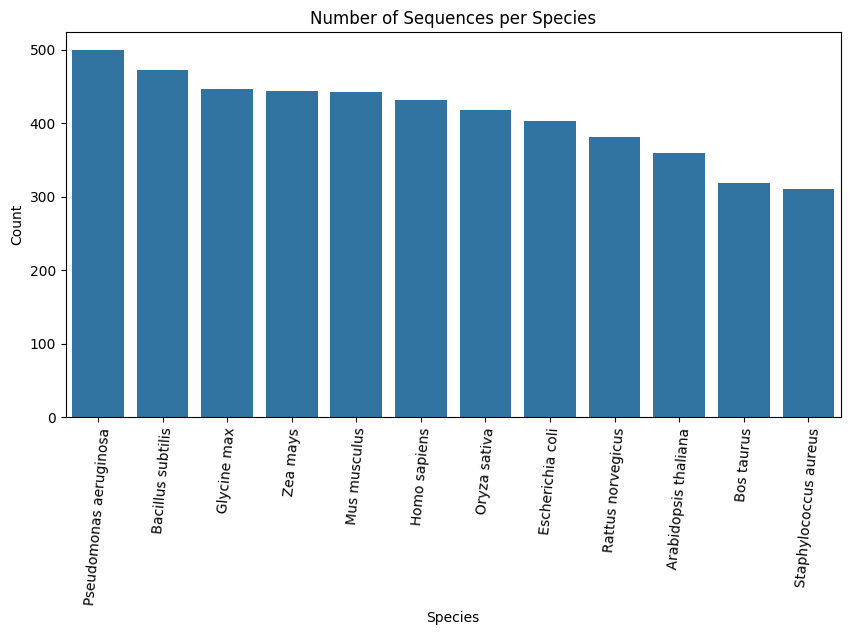

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10,5))
sns.countplot(data=df, x="species", order=df["species"].value_counts().index)
plt.xticks(rotation=85)
plt.title("Number of Sequences per Species")
plt.ylabel("Count")
plt.xlabel("Species")
plt.savefig("species_distribution.pdf", format="pdf", bbox_inches="tight")
plt.show()

#### 2.2 Sequence Length Distribution

This box plot displays the distribution of sequence lengths per species, confirming adherence to the 500-2000 bp length constraints and providing insights into length variability.

###Sequence Length Distribution per Species

#### 2.3 GC Content Distribution

This box plot visualizes the GC content (Guanine and Cytosine percentage) for sequences per species. GC content is a fundamental genomic characteristic used as a discriminative feature in taxonomic classification.

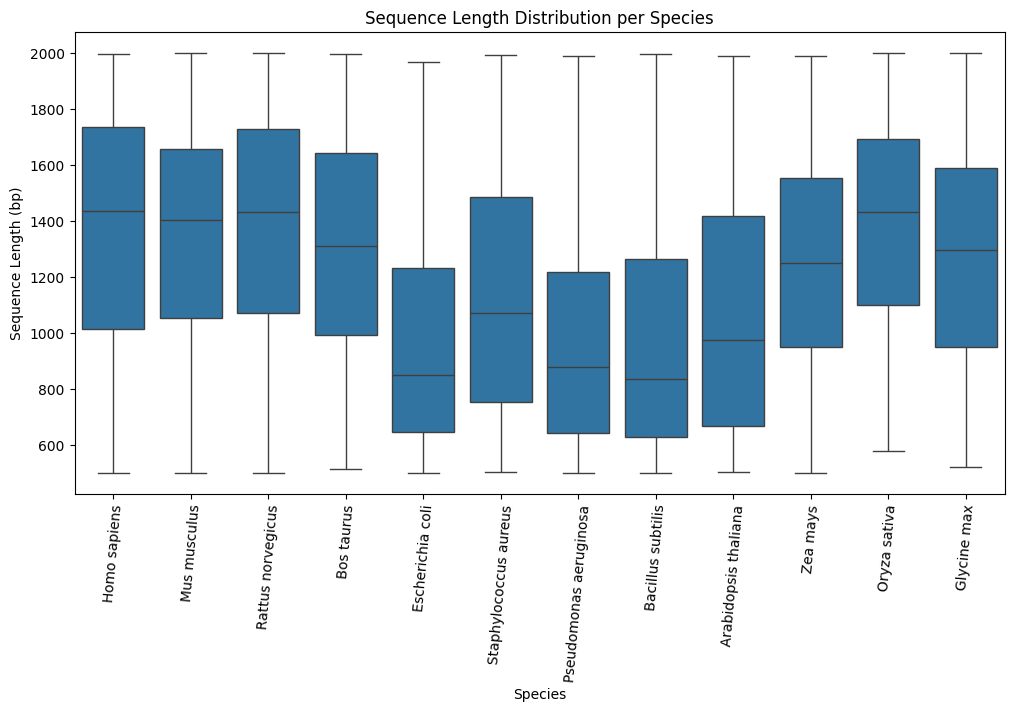

In [ ]:
plt.figure(figsize=(12,6))
sns.boxplot(data=df, x="species", y="length")
plt.xticks(rotation=85)
plt.title("Sequence Length Distribution per Species")
plt.ylabel("Sequence Length (bp)")
plt.xlabel("Species")
plt.savefig("Sequence_Length_Distribution.pdf", format="pdf", bbox_inches="tight")
plt.show()

#### 2.4 K-mer Frequency Heatmap

This section computes and visualizes k-mer (subsequences of length k) frequencies across species. K-mer frequencies are important bioinformatics features, capturing species-specific patterns and biases in genomic composition. The heatmap highlights distinguishing k-mer preferences.

###GC Content per Species

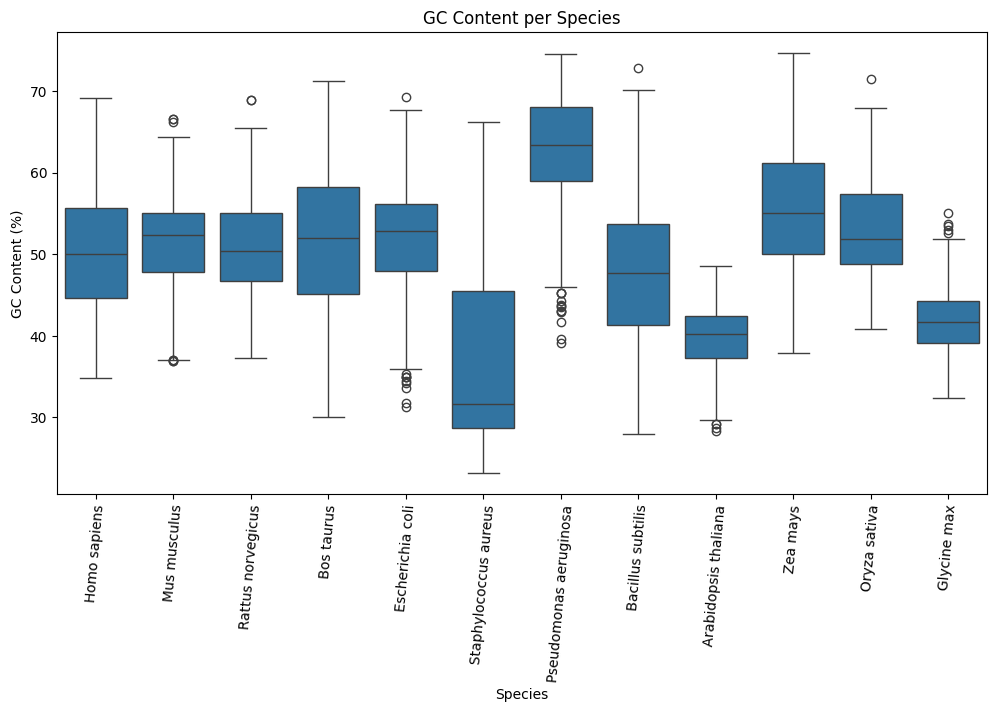

In [ ]:
def gc_content(seq):
    return (seq.count("G") + seq.count("C")) / len(seq) * 100  # percentage

df["gc_content"] = df["sequence"].apply(gc_content)
plt.figure(figsize=(12,6))
sns.boxplot(data=df, x="species", y="gc_content")
plt.xticks(rotation=85)
plt.title("GC Content per Species")
plt.ylabel("GC Content (%)")
plt.xlabel("Species")
plt.savefig("GC_Content.pdf", format="pdf", bbox_inches="tight")
plt.show()

### 3. Data Cleaning and Feature Engineering

This section refines raw sequence data and extracts informative features for machine learning. Data cleaning ensures quality and consistency, while feature engineering transforms sequences into quantitative representations for algorithms.

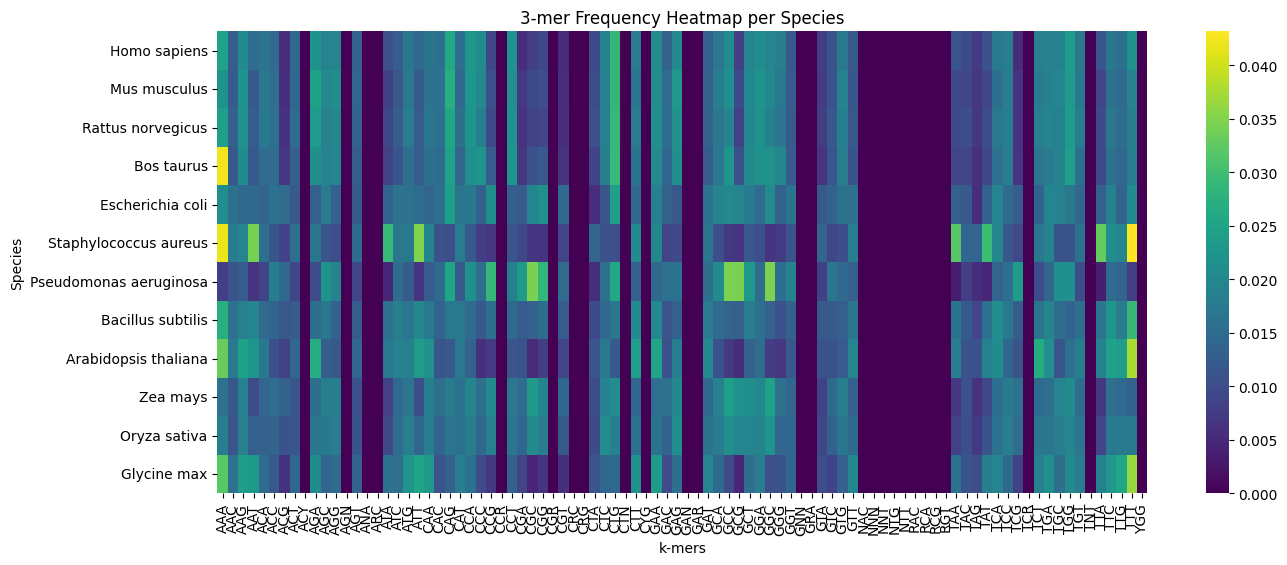

In [ ]:
from collections import Counter
import numpy as np

def kmer_counts(seq, k=3):
    return Counter([seq[i:i+k] for i in range(len(seq)-k+1)])

k = 3
all_kmers = set()
for seq in df["sequence"]:
    all_kmers.update(kmer_counts(seq, k).keys())
all_kmers = sorted(list(all_kmers))

# Compute frequency matrix
freq_matrix = []
for species in df["species"].unique():
    species_seqs = df[df["species"] == species]["sequence"]
    counts = Counter()
    for seq in species_seqs:
        counts.update(kmer_counts(seq, k))
    total = sum(counts.values())
    freq_matrix.append([counts.get(kmer,0)/total for kmer in all_kmers])

# Heatmap
plt.figure(figsize=(15,6))
sns.heatmap(np.array(freq_matrix), xticklabels=all_kmers, yticklabels=df["species"].unique(), cmap="viridis")
plt.title(f"{k}-mer Frequency Heatmap per Species")
plt.xlabel("k-mers")
plt.ylabel("Species")
plt.savefig(f"{k}-mer_Frequency_Heatmap.pdf", format="pdf", bbox_inches="tight")
plt.show()

#### 3.1 Loading and Initial Cleaning

The raw dataset is reloaded and systematically cleaned. This involves standardizing sequence casing, handling missing values, filtering invalid characters, removing duplicates, and enforcing length constraints to ensure data integrity and usability.

In [ ]:
import pandas as pd

df = pd.read_csv("taxonomy_final_dataset.csv")

print(df.head())
print(df.columns)
print(df.shape)

        species domain_group       accession  \
0  Homo sapiens      Metazoa     NR_202033.1   
1  Homo sapiens      Metazoa  NM_001363679.2   
2  Homo sapiens      Metazoa  NM_001445696.1   
3  Homo sapiens      Metazoa  NM_001445669.1   
4  Homo sapiens      Metazoa  NM_001287594.3   

                                            sequence  length  gc_content  
0  GAGACCTGGCGCCGGGCGCTTTGAGGCCCGGCTTACTCCCTTGCTG...    1291    0.467080  
1  CTGGTGCCCTGTTCCGCGTCTGTGCGACCGTCCGTCCCGAGCGCGC...    1608    0.649254  
2  GGGTTCTGCCCGGGGACGCAGCCCAGTTGGTAGCGTCGCTCCCTGA...    1105    0.461538  
3  CTCTTCTCCTGGCGCTCGCGTGCGAGAGGGAACTAGCGAGAACGAG...     991    0.554995  
4  CTCTGATCCAGCCCGGGAGAGGACCGAGCTGGAGGAGCTGGGTGTG...    1085    0.532719  
Index(['species', 'domain_group', 'accession', 'sequence', 'length',
       'gc_content'],
      dtype='object')
(4925, 6)


#### 3.2 Sequence Cleaning and Filtering

This block performs data cleaning for genomic sequences, standardizing characters, removing invalid or missing entries, eliminating duplicates, and applying length filtering. This rigorous process is essential for feature extraction and model training.

In [ ]:
import pandas as pd


df = pd.read_csv("taxonomy_final_dataset.csv")


df["sequence"] = df["sequence"].str.upper()


df = df.dropna(subset=["sequence", "species", "domain_group"])


valid_chars = set("ATCG")

df = df[df["sequence"].apply(lambda x: set(x).issubset(valid_chars))]


df = df.drop_duplicates(subset="sequence")


df = df[(df["length"] >= 500) & (df["length"] <= 2000)]

print("Clean dataset size:", len(df))

Clean dataset size: 4778


#### 3.3 Nucleotide Composition Features

The `nucleotide_composition` function calculates the relative frequencies of A, T, C, and G in a DNA sequence. These fundamental characteristics reflect species-specific genomic biases and aid taxonomic differentiation.

In [ ]:
def nucleotide_composition(seq):
    seq = seq.upper()
    n = len(seq)
    return {
        "A_freq": seq.count("A") / n,
        "T_freq": seq.count("T") / n,
        "C_freq": seq.count("C") / n,
        "G_freq": seq.count("G") / n
    }

#### 3.4 Dinucleotide Frequency Features

The `dinucleotide_frequency` function computes the relative frequencies of all two-base combinations (e.g., 'AA', 'AT'). These provide granular insights into sequence composition, useful for biological analyses like species classification.

In [ ]:
from itertools import product

def dinucleotide_frequency(seq):
    seq = seq.upper()
    dinucs = [''.join(p) for p in product("ATCG", repeat=2)]

    total = len(seq) - 1

    return {
        d: seq.count(d) / total if total > 0 else 0
        for d in dinucs
    }

#### 3.5 Comprehensive Feature Extraction

The `extract_features` function combines nucleotide and dinucleotide frequency calculations to create a comprehensive feature set for each sequence. This standardizes the transformation of raw genomic data into a structured feature vector for machine learning.

In [ ]:
def extract_features(seq):
    features = {}

    features.update(nucleotide_composition(seq))
    features.update(dinucleotide_frequency(seq))

    return features

#### 3.6 Construction of the Feature Matrix

This step applies `extract_features` to each sequence, creating `feature_df`. This `feature_df` is then concatenated with the original `df` to form `df_ml`, a comprehensive dataset with sequence metadata and extracted features, serving as the primary input for machine learning.

In [ ]:
import pandas as pd

feature_df = df["sequence"].apply(extract_features).apply(pd.Series)

df_ml = pd.concat([df, feature_df], axis=1)

#### 3.7 Inspection of the Feature Matrix

This block provides an initial inspection of the constructed feature matrix (`df_ml`). Displaying the DataFrame's head, columns, and shape verifies correct feature engineering and dataset dimensions.

In [ ]:
print(df_ml.head())
print(df_ml.columns)
print(df_ml.shape)

        species domain_group       accession  \
0  Homo sapiens      Metazoa     NR_202033.1   
1  Homo sapiens      Metazoa  NM_001363679.2   
2  Homo sapiens      Metazoa  NM_001445696.1   
3  Homo sapiens      Metazoa  NM_001445669.1   
4  Homo sapiens      Metazoa  NM_001287594.3   

                                            sequence  length  gc_content  \
0  GAGACCTGGCGCCGGGCGCTTTGAGGCCCGGCTTACTCCCTTGCTG...    1291    0.467080   
1  CTGGTGCCCTGTTCCGCGTCTGTGCGACCGTCCGTCCCGAGCGCGC...    1608    0.649254   
2  GGGTTCTGCCCGGGGACGCAGCCCAGTTGGTAGCGTCGCTCCCTGA...    1105    0.461538   
3  CTCTTCTCCTGGCGCTCGCGTGCGAGAGGGAACTAGCGAGAACGAG...     991    0.554995   
4  CTCTGATCCAGCCCGGGAGAGGACCGAGCTGGAGGAGCTGGGTGTG...    1085    0.532719   

     A_freq    T_freq    C_freq    G_freq  ...        TC        TG        CA  \
0  0.231603  0.301317  0.257165  0.209915  ...  0.089922  0.072093  0.068217   
1  0.128731  0.222015  0.347015  0.302239  ...  0.069695  0.094586  0.063472   
2  0.277828  0

### 4. Dataset Partitioning for Machine Learning

The dataset is partitioned into training and testing sets using a stratified splitting strategy. This ensures preservation of taxonomic distribution (species and domain groups) across subsets, preventing biased model training or evaluation.

In [ ]:
df_ml.to_csv("classic_ml.csv", index=False)

#### 4.1 Stratified Train-Test Split

This block performs a stratified train-test split, crucial for maintaining proportional representation of each species and domain group. This minimizes bias in model training and evaluation.

In [ ]:
from sklearn.model_selection import train_test_split


df_ml["stratify_label"] = df_ml["domain_group"] + "_" + df_ml["species"]

X = df_ml[["sequence", "gc_content", "length",'A_freq', 'T_freq', 'C_freq', 'G_freq', 'AA', 'AT', 'AC',
       'AG', 'TA', 'TT', 'TC', 'TG', 'CA', 'CT', 'CC', 'CG', 'GA', 'GT', 'GC',
       'GG']]
y = df_ml[["species", "domain_group"]]
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=df_ml["stratify_label"]
)

train_df = X_train.copy()
train_df[["species", "domain_group"]] = y_train.values

test_df = X_test.copy()
test_df[["species", "domain_group"]] = y_test.values

print("Train size:", len(train_df))
print("Test size:", len(test_df))

train_df.to_csv("train_dataset.csv", index=False)
test_df.to_csv("test_dataset.csv", index=False)

print("Train and test datasets saved successfully.")

Train size: 3822
Test size: 956
Train and test datasets saved successfully.


#### 4.2 Validation of Stratified Split by Domain Group

This visualization compares sequence distribution across domain groups in training and testing datasets. The bar chart confirms effective stratified sampling, showing consistent proportional representation and validating data split integrity for higher-level taxonomic classification.

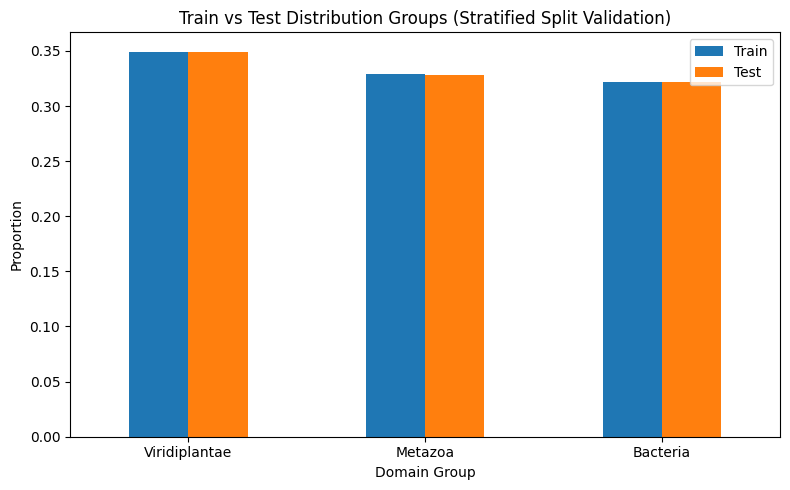

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

train_counts = y_train["domain_group"].value_counts()
test_counts = y_test["domain_group"].value_counts()

train_norm = train_counts / train_counts.sum()
test_norm = test_counts / test_counts.sum()

df_plot = pd.DataFrame({
    "Train": train_norm,
    "Test": test_norm
}).fillna(0)

ax = df_plot.plot(kind="bar", figsize=(8,5))

ax.set_title("Train vs Test Distribution Groups (Stratified Split Validation)")
ax.set_ylabel("Proportion")
ax.set_xlabel("Domain Group")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("train_test_distribution_gr.pdf", format="pdf", bbox_inches="tight")
plt.show()

#### 4.3 Validation of Stratified Split by Species

Similar to domain group validation, this bar chart verifies proportional distribution of individual species within training and testing sets. Consistent species-level representation confirms successful stratification, ensuring diverse and representative model training and evaluation.

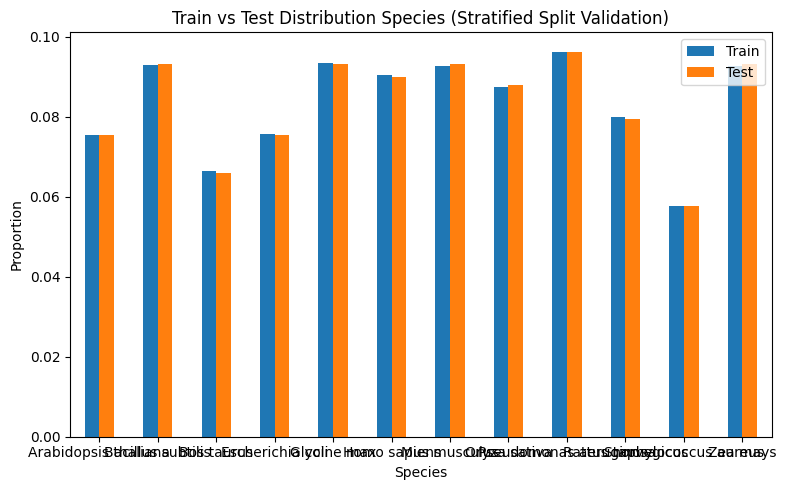

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

train_counts = y_train["species"].value_counts()
test_counts = y_test["species"].value_counts()

train_norm = train_counts / train_counts.sum()
test_norm = test_counts / test_counts.sum()

df_plot = pd.DataFrame({
    "Train": train_norm,
    "Test": test_norm
}).fillna(0)

ax = df_plot.plot(kind="bar", figsize=(8,5))

ax.set_title("Train vs Test Distribution Species (Stratified Split Validation)")
ax.set_ylabel("Proportion")
ax.set_xlabel("Species")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("train_test_distribution.pdf", format="pdf", bbox_inches="tight")
plt.show()